# K Means Clustering algorithm - Implementation 1 (User defined K Value)

In [5]:
import seaborn as sns
from sklearn.datasets import make_blobs

In [6]:
X, y = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    random_state=40
)


In [7]:
X

array([[ -1.3143854 ,  -9.90970266],
       [ -0.25430339,  -6.62246015],
       [ -1.26732591,  -2.4487622 ],
       ...,
       [ -1.83266298, -10.33105963],
       [ -0.40017181,  -4.46109767],
       [ -0.13973822,   2.6070133 ]], shape=(1000, 2))

# Import the required packages from sklearn

In [8]:
from sklearn.cluster import KMeans

### User defines K value

In [9]:
K = 4

kmeans = KMeans(
    n_clusters=K
)

In [10]:
labels = kmeans.fit_predict(X)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


<Axes: >

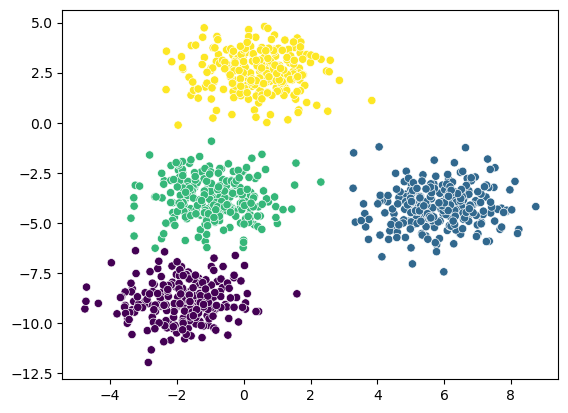

In [11]:
sns.scatterplot(x=X[:,0], y=X[:,1], c=y) # without kmeans 

<Axes: >

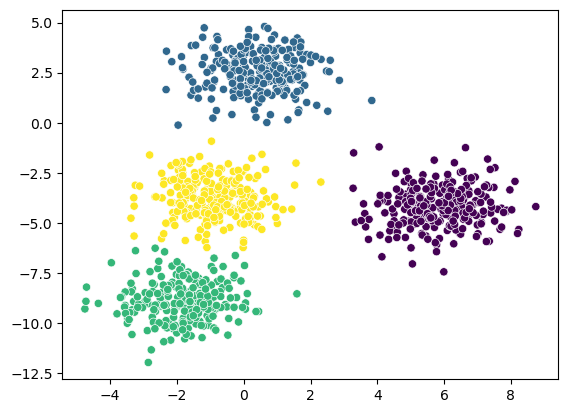

In [12]:
sns.scatterplot(x=X[:,0], y=X[:,1], c=labels) # with kmeans

### Choosing our K value - elbow mthod, silhoutte method 

## Elbow method - manual implementation, automatic implementation

In [17]:
from sklearn.cluster import KMeans
wcss=[]
for k in range(1,21):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit_predict(X)
    wcss.append(kmeans.inertia_)
wcss

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

[27498.133349450207,
 14826.298935990804,
 5284.389575667377,
 1960.9151815208443,
 1766.5273947534442,
 1607.3355465587845,
 1434.8578319500698,
 1330.1100334283392,
 1188.5909979226844,
 1073.672353188807,
 1012.1968403927077,
 939.7779747692399,
 859.6077641245406,
 788.1130534795943,
 757.6824063976848,
 732.7902826101557,
 665.6234506598346,
 682.7841717433852,
 602.3942643486744,
 590.0826540308639]

<Axes: >

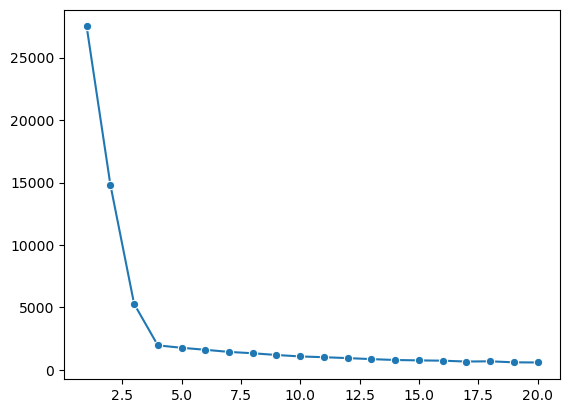

In [18]:
import matplotlib.pyplot as plt
sns.lineplot(x=range(2,21), y=ss, marker='o')
plt.xlabel("K values")
plt.ylabel("Silhouette Score")
plt.title("K vs Silhouette score")
plt.show()

### Elbow method - automatic implementation using Kneed Module

In [19]:
!pip install kneed

In [21]:
from kneed import KneeLocator

In [27]:
knee = KneeLocator(range(1,21), wcss, curve="convex",direction="decreasing")
print("Optimal K value = ",knee.elbow)

Optimal K value =  4


## Implementation of Silhoutte Score

In [29]:
from sklearn.metrics import silhouette_score

In [31]:
ss = []

# range of silhoutette score is always from 2 to n-1
for k in range(2,21):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(X)
    ss.append(silhouette_score(X,labels))
ss

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

[0.4817400091449479,
 0.6442641885862168,
 0.6930066781742424,
 0.5898213855230147,
 0.497186276971145,
 0.49726317117610846,
 0.42481197017384226,
 0.3271074684903323,
 0.32603384252084416,
 0.3371173092220842,
 0.3339840598059179,
 0.32432479637284245,
 0.3203477227586804,
 0.3237992848395771,
 0.3252776851324359,
 0.309122558058192,
 0.31676894831518976,
 0.31805695640876264,
 0.31115139943071113]

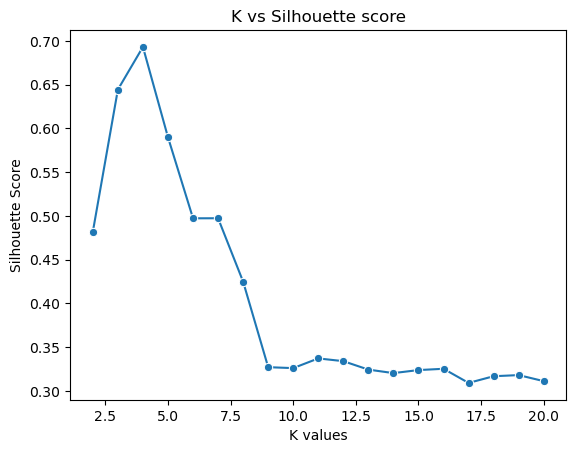

In [37]:
import matplotlib.pyplot as plt
sns.lineplot(x=range(2,21), y=ss, marker='o')
plt.xlabel("K values")
plt.ylabel("Silhouette Score")
plt.title("K vs Silhouette score")
plt.show()

Key points :
1. Silhouette score value are in the range (0,1)
2. The highest silhouette score values give the optimal k value, thus in this case, the highest score is at K = 4